# Pronóstico de consumo a 7 días: comparación de modelos

Objetivo: predecir cuántas unidades de cada producto se van a consumir en los próximos 7 días a partir del historial de salidas.

Este notebook compara 4 métodos con **backtesting**: los ponemos a predecir semanas del pasado cuyo resultado real ya conocemos y medimos cuánto se equivocan.
La explicación completa de cada paso está en `README.md`, en esta misma carpeta.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import torch
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, SeasonalWindowAverage, AutoETS
from chronos import BaseChronosPipeline

H = 7          # horizonte: días a predecir
N_WINDOWS = 4  # cuántas semanas del pasado usamos para evaluar

C:\Users\davfy\Documents\proeycts\tinyml-inventory-forecast\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Cargar los datos

`train.csv` de Kaggle: ventas diarias de 50 productos en 10 tiendas (2013-2017).
Cada combinación tienda+producto es una **serie de tiempo**. `statsforecast` espera tres columnas: `unique_id` (qué serie), `ds` (fecha) y `y` (valor).

In [2]:
raw = pd.read_csv("../data/train.csv", parse_dates=["date"])
df = pd.DataFrame({
    "unique_id": "tienda" + raw.store.astype(str) + "_prod" + raw.item.astype(str),
    "ds": raw.date,
    "y": raw.sales,
})
print(f"{len(df):,} filas | {df.unique_id.nunique()} series | {df.ds.min().date()} a {df.ds.max().date()}")
print(f"Días con 0 ventas: {(df.y == 0).mean():.4%}")
df.head()

913,000 filas | 500 series | 2013-01-01 a 2017-12-31
Días con 0 ventas: 0.0001%


,unique_id,ds,y
0,tienda1_prod1,2013-01-01,13
1,tienda1_prod1,2013-01-02,11
2,tienda1_prod1,2013-01-03,14
3,tienda1_prod1,2013-01-04,13
4,tienda1_prod1,2013-01-05,10


## 2. Mirar los datos antes de modelar

Lo más importante para elegir modelos: ¿hay un patrón que se repite cada semana? (estacionalidad semanal).

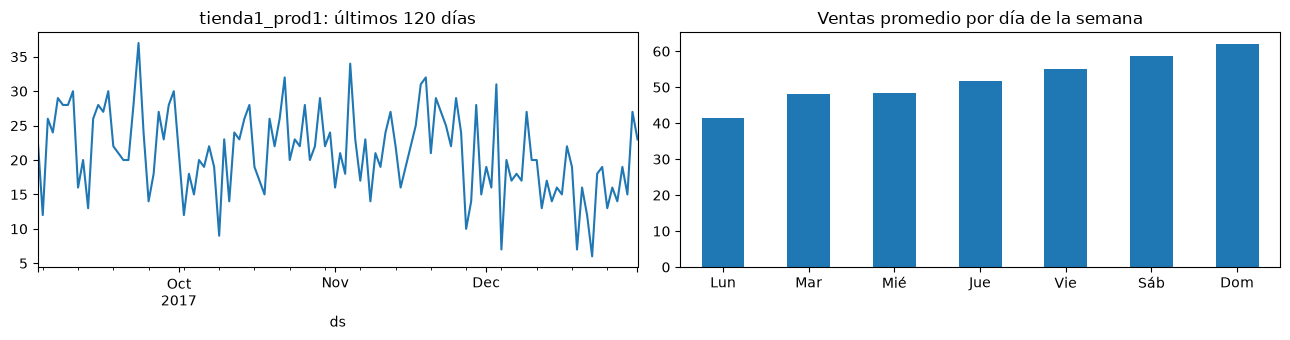

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
df[df.unique_id == "tienda1_prod1"].tail(120).plot(x="ds", y="y", ax=ax[0], legend=False, title="tienda1_prod1: últimos 120 días")
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
df.groupby(df.ds.dt.dayofweek).y.mean().set_axis(dias).plot.bar(ax=ax[1], title="Ventas promedio por día de la semana", rot=0)
plt.tight_layout()

## 3. Backtesting de los modelos estadísticos

`cross_validation` corta el historial en 4 fechas (*cutoffs*), una por semana, al final de 2017. En cada corte, el modelo solo ve los datos hasta esa fecha y predice los 7 días siguientes.
Luego comparamos contra lo que pasó de verdad (columna `y`).

In [4]:
sf = StatsForecast(
    models=[
        SeasonalNaive(season_length=7, alias="Naive_semanal"),                                 # próxima semana = semana pasada
        SeasonalWindowAverage(season_length=7, window_size=4, alias="Promedio_4_semanas"),  # promedio de las últimas 4 semanas, por día
        AutoETS(season_length=7),                                                              # suavizado exponencial, elige su configuración solo
    ],
    freq="D",
    n_jobs=1,  # en Windows, n_jobs=-1 deja procesos colgados
)
cv = sf.cross_validation(df=df, h=H, n_windows=N_WINDOWS, step_size=H)
cv.head()

,unique_id,ds,cutoff,y,Naive_semanal,Promedio_4_semanas,AutoETS
0,tienda10_prod1,2017-12-04,2017-12-03,16.0,23.0,23.75,20.477770
1,tienda10_prod1,2017-12-05,2017-12-03,23.0,23.0,28.00,24.165854
2,tienda10_prod1,2017-12-06,2017-12-03,17.0,28.0,25.50,24.146955
3,tienda10_prod1,2017-12-07,2017-12-03,17.0,36.0,28.50,25.588137
4,tienda10_prod1,2017-12-08,2017-12-03,15.0,22.0,28.25,27.161751


## 4. Backtesting de Chronos (sin entrenar)

Chronos-Bolt es un modelo preentrenado por Amazon. **No lo entrenamos**: en cada corte le damos el historial y nos devuelve la predicción.
Además de la mediana (P50) le pedimos el P10 y el P90, es decir, un rango probable de valores. La primera vez descarga el modelo (~200 MB).

In [5]:
chronos = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu", torch_dtype=torch.float32)

preds = []
for cutoff in sorted(cv.cutoff.unique()):
    historia = df[df.ds <= cutoff].rename(columns={"unique_id": "item_id", "ds": "timestamp", "y": "target"})
    p = chronos.predict_df(historia, prediction_length=H, quantile_levels=[0.1, 0.5, 0.9])
    preds.append(p.assign(cutoff=cutoff))

ch = (pd.concat(preds)
      .rename(columns={"item_id": "unique_id", "timestamp": "ds", "0.5": "Chronos", "0.1": "Chronos_p10", "0.9": "Chronos_p90"})
      [["unique_id", "ds", "cutoff", "Chronos", "Chronos_p10", "Chronos_p90"]])
cv = cv.merge(ch, on=["unique_id", "ds", "cutoff"], how="left")
assert cv["Chronos"].notna().all(), "faltan predicciones de Chronos para algunas fechas"
cv.head()

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Loading weights:  71%|███████▏  | 102/143 [00:00<00:00, 1019.94it/s]

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 1402.05it/s]

,unique_id,ds,cutoff,y,Naive_semanal,Promedio_4_semanas,AutoETS,Chronos,Chronos_p10,Chronos_p90
0,tienda10_prod1,2017-12-04,2017-12-03,16.0,23.0,23.75,20.477770,20.549181,14.981956,27.067055
1,tienda10_prod1,2017-12-05,2017-12-03,23.0,23.0,28.00,24.165854,21.389036,15.210317,28.455727
2,tienda10_prod1,2017-12-06,2017-12-03,17.0,28.0,25.50,24.146955,22.123465,15.723472,29.512751
3,tienda10_prod1,2017-12-07,2017-12-03,17.0,36.0,28.50,25.588137,22.052322,15.569885,29.509668
4,tienda10_prod1,2017-12-08,2017-12-03,15.0,22.0,28.25,27.161751,23.757843,17.161732,31.411003


## 5. Resultados

- **MAE**: en promedio, cuántas unidades por día se equivoca el modelo, para un producto en una tienda. Menos es mejor.
- **WAPE**: error total ÷ ventas totales. "Me equivoco en X% de lo que se vende". Menos es mejor.
- **Sesgo**: si el modelo tiende a predecir de más (+) o de menos (−). Lo ideal es cerca de 0.

In [6]:
modelos = ["Naive_semanal", "Promedio_4_semanas", "AutoETS", "Chronos"]
tabla = pd.DataFrame({
    "MAE (unidades/día)": [(cv[m] - cv.y).abs().mean() for m in modelos],
    "WAPE": [(cv[m] - cv.y).abs().sum() / cv.y.sum() for m in modelos],
    "Sesgo": [(cv[m] - cv.y).sum() / cv.y.sum() for m in modelos],
}, index=modelos).sort_values("MAE (unidades/día)")
tabla.style.format({"MAE (unidades/día)": "{:.2f}", "WAPE": "{:.1%}", "Sesgo": "{:+.1%}"})

,MAE (unidades/día),WAPE,Sesgo
Chronos,6.31,14.2%,+5.2%
AutoETS,7.05,15.9%,+8.3%
Naive_semanal,8.74,19.7%,+5.1%
Promedio_4_semanas,10.63,24.0%,+20.1%


### ¿Cuánto se equivoca en el total de la semana?

Para reabastecer importa el total de la semana más que cada día. Los errores diarios se compensan en parte.

In [7]:
semana = cv.groupby(["unique_id", "cutoff"])[["y"] + modelos].sum()
pd.DataFrame({"WAPE semanal": [(semana[m] - semana.y).abs().sum() / semana.y.sum() for m in modelos]}, index=modelos) \
  .sort_values("WAPE semanal").style.format("{:.1%}")

,WAPE semanal
Chronos,8.4%
Naive_semanal,10.1%
AutoETS,10.9%
Promedio_4_semanas,20.5%


### ¿El P90 de Chronos sirve como "colchón"?

Si el P90 está bien calibrado, las ventas reales deberían quedar por debajo de él cerca del 90% de las veces.

In [8]:
print(f"Ventas reales <= P90: {(cv.y <= cv.Chronos_p90).mean():.1%} de los días (ideal: ~90%)")
print(f"Ventas reales dentro de P10-P90: {cv.y.between(cv.Chronos_p10, cv.Chronos_p90).mean():.1%} (ideal: ~80%)")

Ventas reales <= P90: 94.9% de los días (ideal: ~90%)
Ventas reales dentro de P10-P90: 77.1% (ideal: ~80%)


## 6. Ver una predicción

Última semana evaluada para un producto: lo real vs cada modelo, con la banda P10-P90 de Chronos.

C:\Users\davfy\AppData\Local\Temp\ipykernel_31700\2092111830.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  hist = df[(df.unique_id == "tienda1_prod1") & (df.ds > ej.ds.min() - pd.Timedelta(days=28)) & (df.ds < ej.ds.min())]


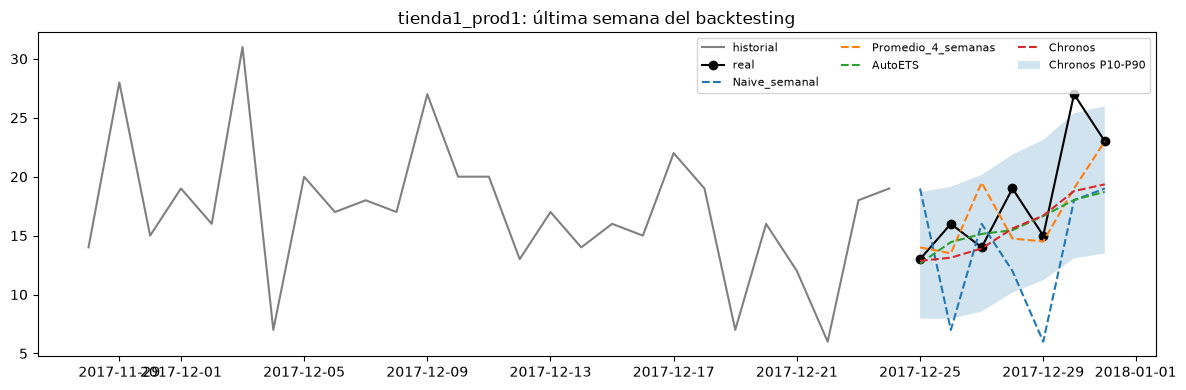

In [9]:
ej = cv[(cv.unique_id == "tienda1_prod1") & (cv.cutoff == cv.cutoff.max())]
hist = df[(df.unique_id == "tienda1_prod1") & (df.ds > ej.ds.min() - pd.Timedelta(days=28)) & (df.ds < ej.ds.min())]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hist.ds, hist.y, color="gray", label="historial")
ax.plot(ej.ds, ej.y, "k-o", label="real")
for m in modelos:
    ax.plot(ej.ds, ej[m], "--", label=m)
ax.fill_between(ej.ds, ej.Chronos_p10, ej.Chronos_p90, alpha=0.2, label="Chronos P10-P90")
ax.legend(ncol=3, fontsize=8)
ax.set_title("tienda1_prod1: última semana del backtesting")
plt.tight_layout()

## 7. Pronóstico real: los próximos 7 días

Esto es lo que haría el servicio en la Raspberry Pi una vez al día: tomar todo el historial y predecir la próxima semana.
Redondeamos porque se consumen unidades enteras. `total_p90` es la suma de los P90 de cada día: como los errores diarios se compensan en parte, queda por encima del P90 real de la semana. Es un número conservador para reabastecer.

In [10]:
p = chronos.predict_df(df.rename(columns={"unique_id": "item_id", "ds": "timestamp", "y": "target"}),
                       prediction_length=H, quantile_levels=[0.5, 0.9])
prox = (p.groupby("item_id")[["0.5", "0.9"]].sum().apply(lambda s: s.round().astype(int))
         .rename(columns={"0.5": "total_7d_p50", "0.9": "total_p90"}))
print("Fechas:", p.timestamp.min().date(), "a", p.timestamp.max().date())
prox.head(10)

Fechas: 2018-01-01 a 2018-01-07


,total_7d_p50,total_p90
item_id,,
tienda10_prod1,138,189
tienda10_prod10,492,582
tienda10_prod11,512,602
tienda10_prod12,516,589
tienda10_prod13,585,679
tienda10_prod14,401,481
tienda10_prod15,614,711
tienda10_prod16,163,215
tienda10_prod17,232,291
